In [7]:
import pandas as pd

xls = pd.ExcelFile("Online Retail.xlsx")
df = pd.read_excel(xls, sheet_name=xls.sheet_names[0])

df_clean = df[df["order_status"] == "Approved"].copy()
df_clean["transaction_date"] = pd.to_datetime(df_clean["transaction_date"])

print("Approved transactions:", len(df_clean))
print("Unique customers:", df_clean["customer_id"].nunique())
df_clean.head()

Approved transactions: 19821
Unique customers: 3493


,transaction_id,product_id,customer_id,transaction_date,online_order,order_status,brand,product_line,product_class,product_size,list_price,standard_cost,product_first_sold_date
0,1,2,2950,2017-02-25,0.0,Approved,Solex,Standard,medium,medium,71.49,53.62,41245.0
1,2,3,3120,2017-05-21,1.0,Approved,Trek Bicycles,Standard,medium,large,2091.47,388.92,41701.0
2,3,37,402,2017-10-16,0.0,Approved,OHM Cycles,Standard,low,medium,1793.43,248.82,36361.0
3,4,88,3135,2017-08-31,0.0,Approved,Norco Bicycles,Standard,medium,medium,1198.46,381.10,36145.0
4,5,78,787,2017-10-01,1.0,Approved,Giant Bicycles,Standard,medium,large,1765.30,709.48,42226.0


In [8]:
# 1. Year-month of each transaction
df_clean["OrderMonth"] = df_clean["transaction_date"].dt.to_period("M")

# 2. Each customer's first purchase month (their cohort)
df_clean["CohortMonth"] = df_clean.groupby("customer_id")["OrderMonth"].transform("min")

# 3. Months passed since first purchase (0 = acquisition month)
year_diff = df_clean["OrderMonth"].dt.year - df_clean["CohortMonth"].dt.year
month_diff = df_clean["OrderMonth"].dt.month - df_clean["CohortMonth"].dt.month
df_clean["CohortIndex"] = year_diff * 12 + month_diff

df_clean[["customer_id", "transaction_date", "OrderMonth", "CohortMonth", "CohortIndex"]].head(10)

,customer_id,transaction_date,OrderMonth,CohortMonth,CohortIndex
0,2950,2017-02-25,2017-02,2017-02,0
1,3120,2017-05-21,2017-05,2017-01,4
2,402,2017-10-16,2017-10,2017-01,9
3,3135,2017-08-31,2017-08,2017-02,6
4,787,2017-10-01,2017-10,2017-01,9
5,2339,2017-03-08,2017-03,2017-02,1
6,1542,2017-04-21,2017-04,2017-02,2
7,2459,2017-07-15,2017-07,2017-04,3
8,1305,2017-08-10,2017-08,2017-02,6
9,3262,2017-08-30,2017-08,2017-01,7


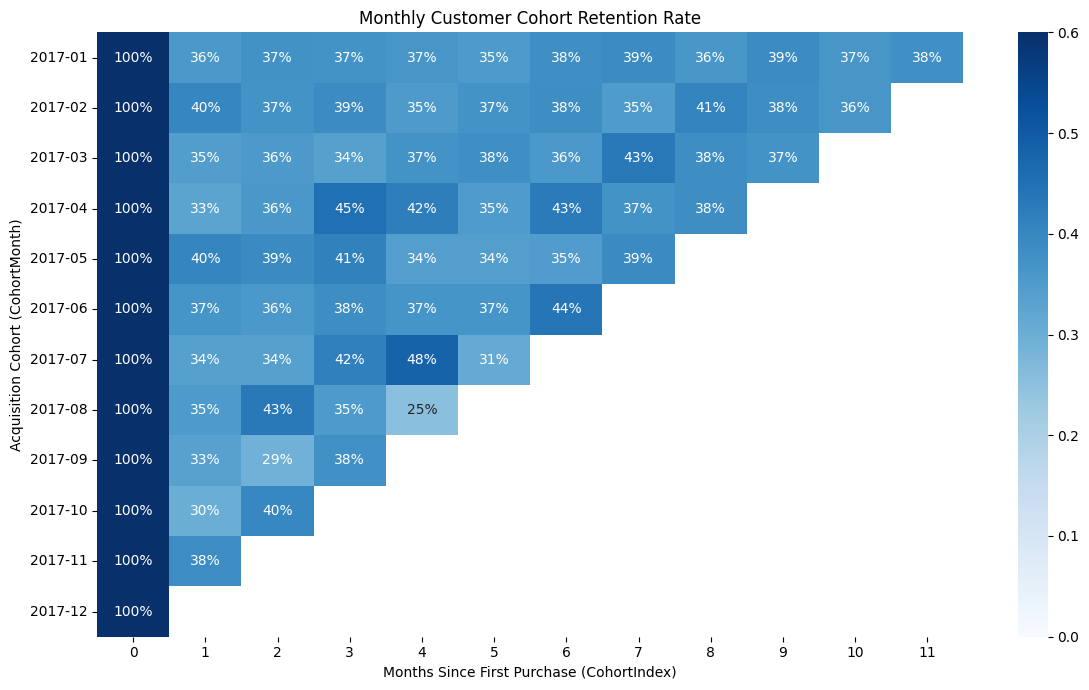

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count unique customers in each cohort and month index
cohort_data = (
    df_clean.groupby(["CohortMonth", "CohortIndex"])["customer_id"]
    .nunique()
    .reset_index()
)

# Reshape into a table: rows = CohortMonth, columns = CohortIndex
cohort_counts = cohort_data.pivot(
    index="CohortMonth", columns="CohortIndex", values="customer_id"
)

# Divide by column 0 (initial cohort size) to get retention rates
cohort_sizes = cohort_counts.iloc[:, 0]
retention = cohort_counts.divide(cohort_sizes, axis=0)

# Plot the heatmap
plt.figure(figsize=(12, 7))
sns.heatmap(retention, annot=True, fmt=".0%", cmap="Blues", vmin=0.0, vmax=0.6)
plt.title("Monthly Customer Cohort Retention Rate")
plt.xlabel("Months Since First Purchase (CohortIndex)")
plt.ylabel("Acquisition Cohort (CohortMonth)")
plt.tight_layout()
plt.show()

In [10]:
# Reference end date of the dataset
max_date = df_clean["transaction_date"].max()

# Summarize each customer's purchasing behavior
cust_df = df_clean.groupby("customer_id").agg(
    last_order_date=("transaction_date", "max"),
    total_orders=("transaction_id", "count"),
    total_spend=("list_price", "sum"),
    online_share=("online_order", "mean")
).reset_index()

# Days since last purchase, and churn flag (> 90 inactive days = 1, else 0)
cust_df["recency_days"] = (max_date - cust_df["last_order_date"]).dt.days
cust_df["Churned"] = (cust_df["recency_days"] > 90).astype(int)

print("Total customers:", len(cust_df))
print("Churn rate (>90 days inactive):", f"{cust_df['Churned'].mean():.1%}")
print(cust_df.groupby("Churned")[["recency_days", "total_orders", "total_spend"]].mean().round(2))
cust_df.head()

Total customers: 3493
Churn rate (>90 days inactive): 23.1%
         recency_days  total_orders  total_spend
Churned                                         
0               35.14          6.08      6711.64
1              148.06          4.32      4865.83


,customer_id,last_order_date,total_orders,total_spend,online_share,recency_days,Churned
0,1,2017-12-23,11,9084.45,0.545455,7,0
1,2,2017-08-24,3,4149.07,0.333333,128,1
2,3,2017-09-19,8,9888.23,0.142857,102,1
3,4,2017-06-18,2,1047.72,0.500000,195,1
4,5,2017-12-14,6,5903.20,0.333333,16,0


In [11]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split

# Add average order value and profit margin per customer
cust_df["avg_order_value"] = cust_df["total_spend"] / cust_df["total_orders"]
cust_df["margin"] = df_clean.groupby("customer_id").apply(
    lambda g: (g["list_price"] - g["standard_cost"]).sum()
).reindex(cust_df["customer_id"]).fillna(0).values
cust_df["online_share"] = cust_df["online_share"].fillna(cust_df["online_share"].median())

features = ["total_orders", "total_spend", "avg_order_value", "online_share", "margin"]
X = cust_df[features]
y = cust_df["Churned"]

# 80/20 stratified split so churn proportion stays balanced in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob), 3))
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=3))

/tmp/ipykernel_6594/3841769447.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cust_df["margin"] = df_clean.groupby("customer_id").apply(


ROC-AUC Score: 0.724

Classification Report:
               precision    recall  f1-score   support

           0      0.802     0.968     0.877       538
           1      0.653     0.199     0.305       161

    accuracy                          0.791       699
   macro avg      0.727     0.584     0.591       699
weighted avg      0.767     0.791     0.745       699



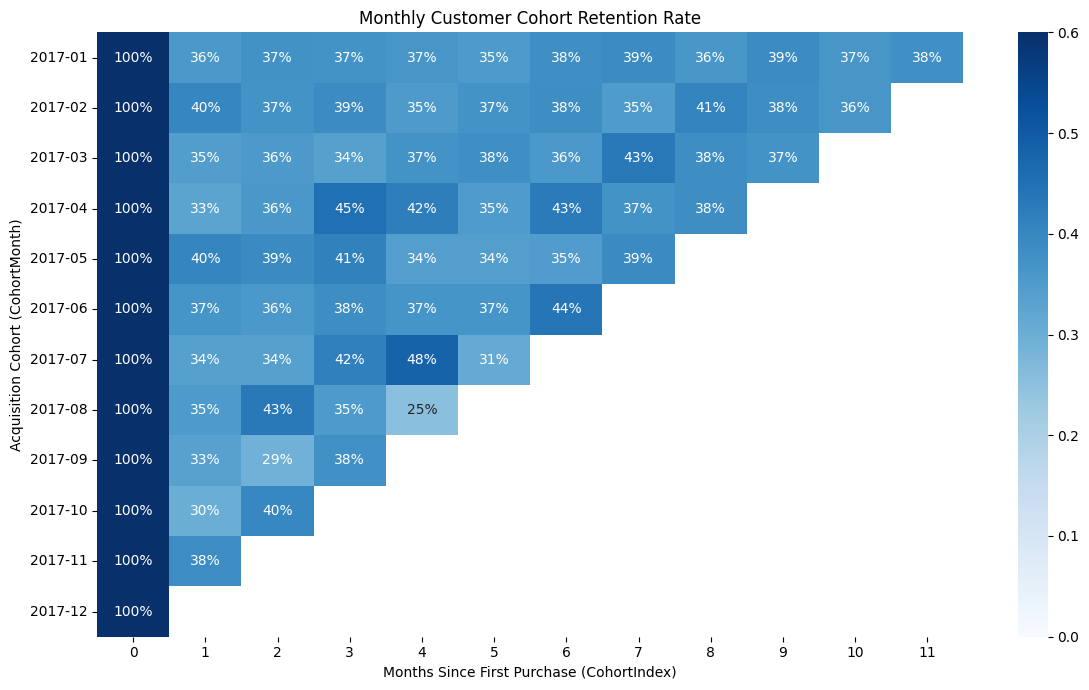

Churn rate (%) by total orders:
 total_orders
1     69.4
2     58.8
3     38.0
4     28.6
5     25.7
6     18.3
7     12.4
8      9.4
9      6.0
10     2.4
Name: Churned, dtype: float64


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Re-save high-resolution cohort heatmap to Colab files
plt.figure(figsize=(12, 7))
sns.heatmap(retention, annot=True, fmt=".0%", cmap="Blues", vmin=0.0, vmax=0.6)
plt.title("Monthly Customer Cohort Retention Rate")
plt.xlabel("Months Since First Purchase (CohortIndex)")
plt.ylabel("Acquisition Cohort (CohortMonth)")
plt.tight_layout()
plt.savefig("cohort_retention_heatmap.png", dpi=300)
plt.show()

# Print churn rate by order count (capped at 10+ orders)
order_bucket = cust_df["total_orders"].clip(upper=10)
churn_by_orders = cust_df.groupby(order_bucket)["Churned"].mean() * 100
print("Churn rate (%) by total orders:\n", churn_by_orders.round(1))